In [23]:
import os

# Задаем переменные окружения для Kaggle API
os.environ['KAGGLE_USERNAME'] = "Nukiesto"
os.environ['KAGGLE_KEY'] = "KGAT_1740e3ac04cbc99ab2cda2578585c715"

# Скачивание датасета "Student Performance - Multiple Linear Regression"
!kaggle datasets download -d nikhil7280/student-performance-multiple-linear-regression

# Распаковка архива
!unzip -o student-performance-multiple-linear-regression.zip

Dataset URL: https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression
License(s): other
student-performance-multiple-linear-regression.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  student-performance-multiple-linear-regression.zip
  inflating: Student_Performance.csv  


In [25]:
import pandas as pd
from IPython.display import display

df = pd.read_csv('Student_Performance.csv')

display(df.head())
display(df.describe().round(2))

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,4.99,69.45,6.53,4.58,55.22
std,2.59,17.34,1.70,2.87,19.21
min,1.00,40.00,4.00,0.00,10.00
25%,3.00,54.00,5.00,2.00,40.00
50%,5.00,69.00,7.00,5.00,55.00
75%,7.00,85.00,8.00,7.00,71.00
max,9.00,99.00,9.00,9.00,100.00


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_percentage_error
from sklearn.exceptions import ConvergenceWarning

class MLR_Sklearn(object):

  def __init__(self, X, y, normalization=False):
    self.m = X.shape[0]
    self.n = X.shape[1]
    self.normalization = normalization
    self.scaler = StandardScaler() if normalization else None

    self.X_orig = X
    self.y = y.ravel()

    if self.normalization:
      self.X = self.scaler.fit_transform(X)
    else:
      self.X = X

    self.model_NE = LinearRegression()
    # warm_start=True позволяет продолжать обучение с предыдущих весов
    self.model_GD = SGDRegressor(max_iter=1, warm_start=True, random_state=42, learning_rate='constant')

    self.history = []
    self.R_2_NE = 0.
    self.R_2_GD = 0.
    self.mean_approximation_error_NE = 100.
    self.mean_approximation_error_GD = 100.

  def summary(self):
    w_ne_full = np.concatenate(([self.model_NE.intercept_], self.model_NE.coef_)) if hasattr(self.model_NE, 'coef_') else np.zeros(self.n + 1)
    w_gd_full = np.concatenate(([self.model_GD.intercept_[0]], self.model_GD.coef_)) if hasattr(self.model_GD, 'coef_') else np.zeros(self.n + 1)

    print('-' * 80,
          'Observations: ' + str(self.m),
          'Features: ' + str(self.n),
          'Weights (NE): ' + str(w_ne_full),
          'Weights (GD): ' + str(w_gd_full),
          'Itarations: ' + str(len(self.history)),
          'R^2 (NE): ' + str(self.R_2_NE),
          'R^2 (GD): ' + str(self.R_2_GD),
          'Mean approximation error (NE): ' +
          str(self.mean_approximation_error_NE),
          'Mean approximation error (GD): ' +
          str(self.mean_approximation_error_GD),
          '-' * 80, sep='\n')

  def cost_function(self, y_true, y_pred):
      residuals = y_pred - y_true
      cost = np.dot(residuals, residuals) / (2 * self.m)
      return cost

  def fitNE(self):
    self.model_NE.fit(self.X, self.y)

  def fitGD(self, eta0=0.05, tol=1e-5, max_iter=1000):
    self.history.clear()
    self.model_GD.set_params(eta0=eta0, max_iter=1)

    # Подавляем ConvergenceWarning, так как сами контролируем цикл
    warnings.filterwarnings("ignore", category=ConvergenceWarning)

    for i in range(max_iter):
        self.model_GD.fit(self.X, self.y)

        y_pred = self.model_GD.predict(self.X)
        cost = self.cost_function(self.y, y_pred)
        self.history.append(cost)

        if i > 0 and abs(self.history[-2] - self.history[-1]) < tol:
             break

  def predict(self, X_test, y_test, method_of_computation=True):
    if self.normalization:
      X_test_prepared = self.scaler.transform(X_test)
    else:
      X_test_prepared = X_test

    y_test_1d = y_test.ravel()

    if method_of_computation:
      y_predict = self.model_NE.predict(X_test_prepared)
      self.R_2_NE = r2_score(y_test_1d, y_predict)
      self.mean_approximation_error_NE = mean_absolute_percentage_error(y_test_1d, y_predict) * 100
    else:
      y_predict = self.model_GD.predict(X_test_prepared)
      self.R_2_GD = r2_score(y_test_1d, y_predict)
      self.mean_approximation_error_GD = mean_absolute_percentage_error(y_test_1d, y_predict) * 100

    return y_predict.reshape(-1, 1)

  def depict(self):
    n = min(50, len(self.history))
    print(f"Number of itarations selected for plotting: {n}")
    n_axis = np.arange(len(self.history))
    plt.figure()
    plt.plot(n_axis[0:n], self.history[0:n])
    plt.xlabel('Number of itarations')
    plt.ylabel('Cost function')
    plt.show()

In [14]:
df = pd.read_csv('Student_Performance.csv')
df_copy = df.copy()

for i in range(0, len(df)):
  if df_copy['Extracurricular Activities'][i] == 'Yes':
    df_copy.at[i, 'Extracurricular Activities'] = 1
  else:
    df_copy.at[i, 'Extracurricular Activities'] = 0

index = list(range(0, len(df)))
np.random.seed(42) # Фиксируем seed для стабильности разбиения
index = np.random.permutation(index)
index_train = index[0: int(0.6 * len(df))]
index_test = index[int(0.6 * len(df)): len(df)]
train_data = df_copy.iloc[index_train]
test_data = df_copy.iloc[index_test]

X_train = train_data.loc[ :, ['Hours Studied', 'Previous Scores',
                              'Extracurricular Activities',
                              'Sleep Hours',
                              'Sample Question Papers Practiced']]
y_train = train_data.loc[:, ['Performance Index']]

X_train = X_train.to_numpy(dtype=np.float64)
y_train = y_train.to_numpy(dtype=np.float64)

X_test = test_data.loc[ :, ['Hours Studied', 'Previous Scores',
                            'Extracurricular Activities',
                            'Sleep Hours',
                            'Sample Question Papers Practiced']]
y_test = test_data.loc[:, ['Performance Index']]

X_test = X_test.to_numpy(dtype=np.float64)
y_test = y_test.to_numpy(dtype=np.float64)

============== МОДЕЛЬ БЕЗ НОРМАЛИЗАЦИИ ==============
--------------------------------------------------------------------------------
Observations: 6000
Features: 5
Weights (NE): [-34.26009924   2.84932965   1.02004285   0.63745178   0.481161
   0.20441763]
Weights (GD): [-34.22282693   2.8461966    0.97138885   0.49884769   0.45823212
   0.1718453 ]
Itarations: 256
R^2 (NE): 0.9886528631746885
R^2 (GD): 0.9475053897915034
Mean approximation error (NE): 3.426374310812234
Mean approximation error (GD): 7.371461912393364
--------------------------------------------------------------------------------
Number of itarations selected for plotting: 50


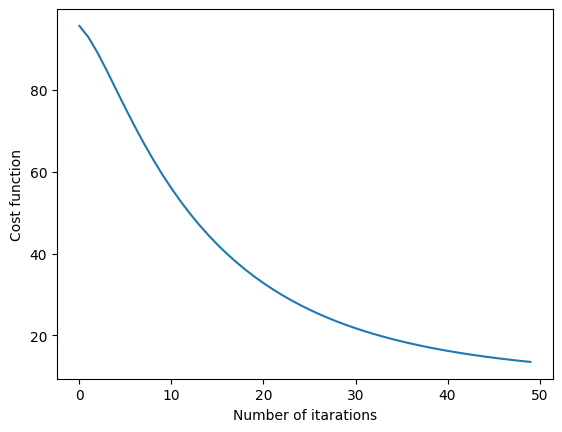

In [15]:
print("============== МОДЕЛЬ БЕЗ НОРМАЛИЗАЦИИ ==============")
# Используем eta0 вместо alpha и tol вместо epsilon для sklearn SGDRegressor
model_students = MLR_Sklearn(X_train, y_train)
model_students.fitNE()
model_students.fitGD(eta0=0.0003, tol=0.00001, max_iter=1000)

model_students.predict(X_test, y_test)
model_students.predict(X_test, y_test, method_of_computation=False)
model_students.summary()
model_students.depict()


============== МОДЕЛЬ С НОРМАЛИЗАЦИЕЙ ==============
--------------------------------------------------------------------------------
Observations: 6000
Features: 5
Weights (NE): [55.032       7.33674567 17.69353434  0.31871808  0.81634462  0.581556  ]
Weights (GD): [ 8.68644453e+11  5.02178752e+11 -1.41994813e+11  5.72890440e+11
  4.30187751e+11 -1.77145057e+11]
Itarations: 1000
R^2 (NE): 0.9886528631746885
R^2 (GD): -4.0370100469249747e+21
Mean approximation error (NE): 3.426374310812233
Mean approximation error (GD): 2013562448214.5393
--------------------------------------------------------------------------------
Number of itarations selected for plotting: 50


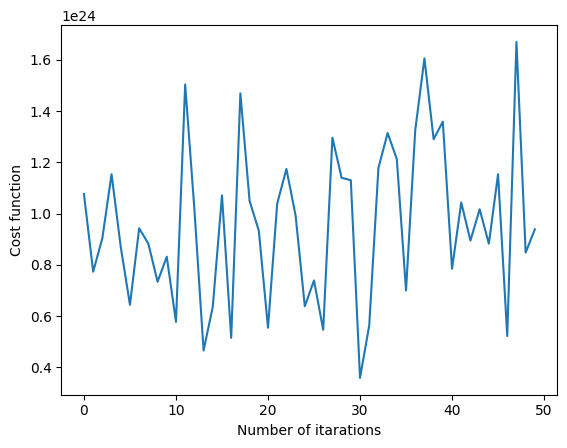

In [16]:
print("\n============== МОДЕЛЬ С НОРМАЛИЗАЦИЕЙ ==============")
model_students_normalized = MLR_Sklearn(X_train, y_train, normalization=True)
model_students_normalized.fitNE()
model_students_normalized.fitGD(eta0=0.5, tol=0.00001, max_iter=1000)

model_students_normalized.predict(X_test, y_test)
model_students_normalized.predict(X_test, y_test, method_of_computation=False)
model_students_normalized.summary()
model_students_normalized.depict()